# 2D Waterfalls, Diagnostic Cards, Subband Folding & Slider Lab

Demonstrates:
1. `extract_segment_waterfall`, S/N-preserving `bin2d`, and `plot_candidate_diagnostic_card`.
2. Headless `WaterfallLabState` slider refolding.
3. Non-wrapping dispersive `fold_subbands` (2D `freq_subband x phase` waterfall + spectrum).

Waterfall GLRT S/N = 19.50 (w=1), rebinned=(8, 16)


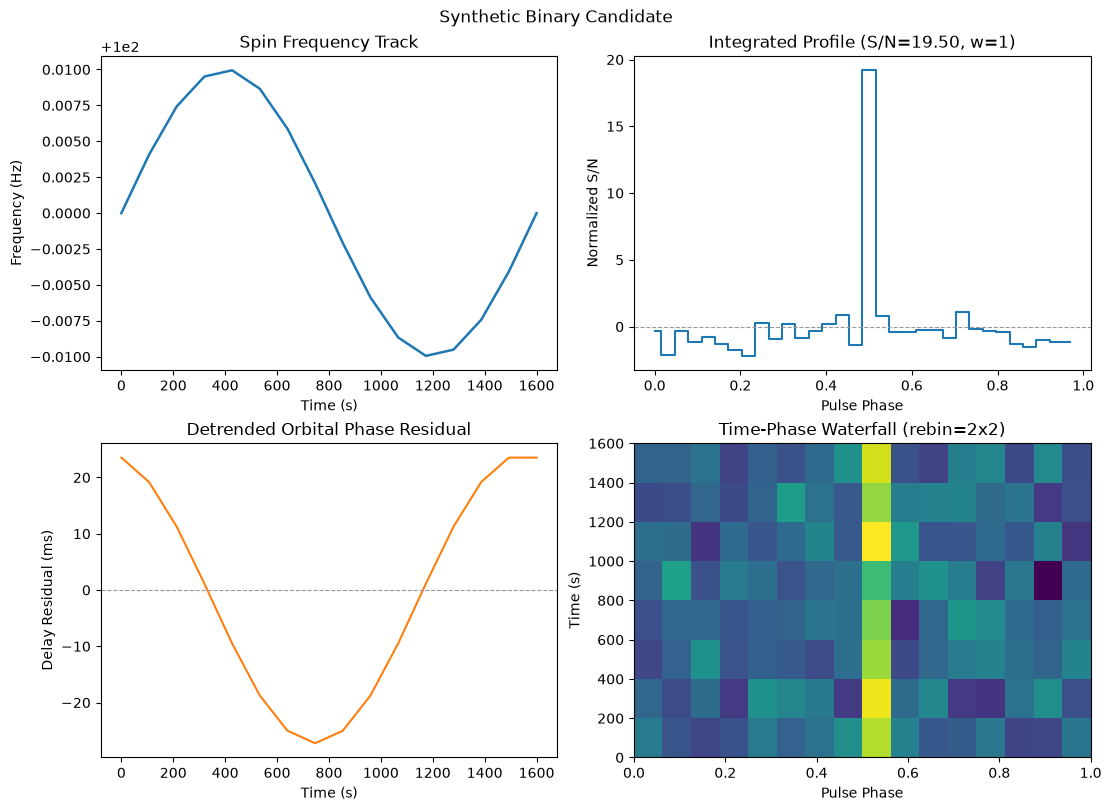

In [1]:
import numpy as np
from matplotlib import pyplot as plt

from pyloki.apps.pyloki_viewer import WaterfallLabParams, WaterfallLabState
from pyloki.io.cands import (
    bin2d,
    extract_segment_waterfall,
    plot_candidate_diagnostic_card,
)
from pyloki.io.timeseries import K_DM_CONST, fold_subbands

rng = np.random.default_rng(19)
n_seg, n_bins = 16, 32
t_seg = np.linspace(0.0, 1600.0, n_seg)
folds = np.empty((n_seg, 2, n_bins), dtype=np.float32)
folds[:, 0, :] = rng.normal(0.0, 1.0, size=(n_seg, n_bins))
folds[:, 1, :] = 1.0
shifts = np.arange(n_seg, dtype=np.int64) % 6
for i in range(n_seg):
    folds[i, 0, (16 - int(shifts[i])) % n_bins] += 5.0

wf = extract_segment_waterfall(folds, phase_shifts=shifts)
rebinned = bin2d(wf.amp_map, bt=2, bp=2)
print(
    f"Waterfall GLRT S/N = {wf.best_snr:.2f} (w={wf.best_width}), "
    f"rebinned={rebinned.shape}"
)

fig = plot_candidate_diagnostic_card(
    wf,
    t_seg,
    100.0 + 0.01 * np.sin(2.0 * np.pi * t_seg / 1600.0),
    rebin=(2, 2),
    title="Synthetic Binary Candidate",
)
plt.show()

In [2]:
# Headless WaterfallLabState slider refolding
state = WaterfallLabState(wf.segment_folds, t_seg, f0_ref=100.0)
state.params = WaterfallLabParams(delta_f0=0.0, time_rebin=2, phase_rebin=1)
_, _, lab_snr = state.compute()
print(f"WaterfallLabState S/N = {lab_snr:.2f}")

# Non-wrapping dispersive (freq_subband x phase) folding
n_chan, n_samp, dt = 16, 4096, 5e-4
freqs = np.linspace(1500.0, 1200.0, n_chan)
dm_true, f0 = 40.0, 20.0
data = rng.normal(0.0, 1.0, size=(n_chan, n_samp)).astype(np.float32)
times = np.arange(n_samp) * dt
nu_ref = float(np.max(freqs))
for c in range(n_chan):
    delay = K_DM_CONST * dm_true * (freqs[c] ** -2 - nu_ref**-2)
    phase = np.mod(f0 * (times - delay), 1.0)
    pulse = np.where((times >= delay) & (np.abs(phase - 0.5) < 0.04), 3.0, 0.0)
    data[c] += pulse.astype(np.float32)

sub = fold_subbands(
    data,
    dm=dm_true,
    phase_func=lambda t: f0 * t,
    n_subbands=8,
    n_bins=32,
    tsamp=dt,
    chan_freqs_mhz=freqs,
    zap_channels=[3],
)
print(
    f"Subband peak profile S/N = {float(np.max(sub.integrated_profile)):.2f}, "
    f"mean spectrum = {float(np.mean(sub.spectrum)):.2f}"
)

WaterfallLabState S/N = 19.50
Subband peak profile S/N = 106.60, mean spectrum = 49.71
